# K-Nearest Neighbors (KNN): Glass Identification
Yuchan Jun, myles lewis

**Goal:** Predict glass type using refractive index and chemical composition. Data source: UCI Glass Identification (uploaded file). The original identifiers are **not** used as predictors.

**Workflow:** inspect → split → standardize training data → tune K on cross-validation → evaluate on held-out test set. Standardization belongs inside the training pipeline to prevent data leakage.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from pathlib import Path
DATA = Path('data')
if not DATA.exists():
    DATA = Path('KNN_NB_assignment/data')

columns = ['id','RI','Na','Mg','Al','Si','K','Ca','Ba','Fe','glass_type']
df = pd.read_csv(DATA/'glass.data', header=None, names=columns)
display(df.head());print('Shape:',df.shape);print('Class counts:');print(df.glass_type.value_counts().sort_index())

,id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,glass_type
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Shape: (214, 11)
Class counts:
glass_type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


Best K: 3
Test accuracy: 0.796
              precision    recall  f1-score   support

           1       0.79      0.83      0.81        18
           2       0.75      0.95      0.84        19
           3       1.00      0.25      0.40         4
           5       1.00      0.33      0.50         3
           6       1.00      0.50      0.67         2
           7       0.88      0.88      0.88         8

    accuracy                           0.80        54
   macro avg       0.90      0.62      0.68        54
weighted avg       0.82      0.80      0.78        54



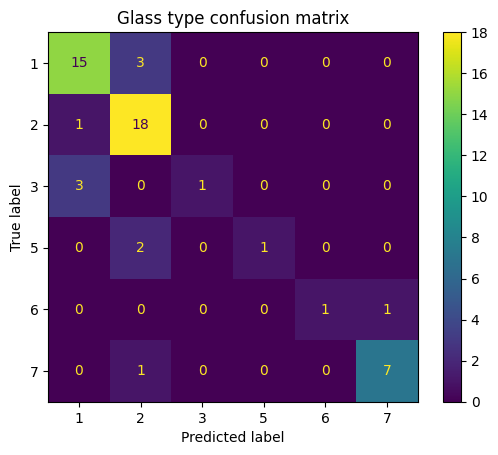

In [ ]:
X = df.drop(columns=['id','glass_type'])
y = df['glass_type']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
pipe = Pipeline([('scale',StandardScaler()),('knn',KNeighborsClassifier())])
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
search=GridSearchCV(pipe, {'knn__n_neighbors':[3,5,7,9,11]},cv=cv,scoring='accuracy')
search.fit(X_train,y_train)
pred=search.predict(X_test)
acc=accuracy_score(y_test,pred)
print('Best K:',search.best_params_['knn__n_neighbors']);print(f'Test accuracy: {acc:.3f}')
print(classification_report(y_test,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred);plt.title('Glass type confusion matrix');plt.show()

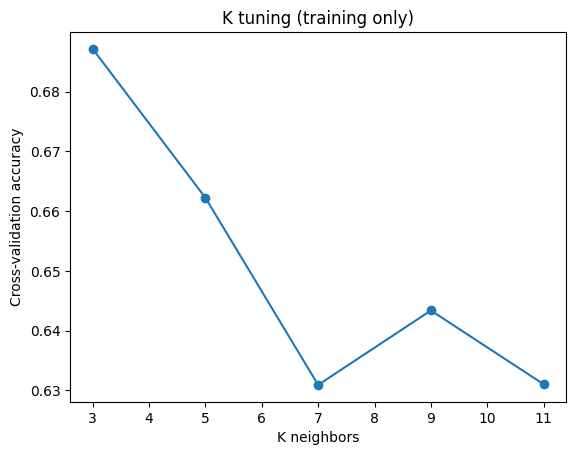

In [ ]:
results=pd.DataFrame(search.cv_results_)[['param_knn__n_neighbors','mean_test_score']]
results.plot(x='param_knn__n_neighbors',y='mean_test_score',marker='o',legend=False)
plt.xlabel('K neighbors');plt.ylabel('Cross-validation accuracy');plt.title('K tuning (training only)');plt.show()

## Explain
The model identifies a type of glass by comparing its chemical measurements with those of previously labeled samples. Each new sample is assigned the glass type most common among its nearest neighbors. **Run the notebook and use the test accuracy printed above** to complete this sentence: “The model correctly identified approximately ___ out of 100 unseen glass samples.” Some types are harder to distinguish because the chemical measurements can overlap. This is a classification aid, not proof of a glass sample’s origin.

**Limitations:** This small dataset has uneven class sizes, so consult class-level recall and the confusion matrix rather than accuracy alone.